In [1]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import gc
import json
import os
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
SOURCE = ROOT / "data" / "processed" / "brfss_2024_brut.parquet"
FACTEURS = [0.10, 0.25, 0.50, 1.0, 2.0, 3.0]
REPETITIONS = 5
GRAINE = 42
LIGNES_PAR_GROUPE = 50_000
N_WORKERS = min(4, os.cpu_count() or 1)
SEUIL_IMC = 30

RUN = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RESULTS = ROOT / "results" / f"benchmark_{RUN}"
DATASETS = ROOT / "data" / "processed" / f"benchmark_{RUN}"

if not SOURCE.is_file():
    raise FileNotFoundError(f"Fichier attendu : {SOURCE}. Vérifie le dossier de travail : {ROOT}")
assert REPETITIONS >= 2
assert FACTEURS and len(set(FACTEURS)) == len(FACTEURS)
assert all(f in [0.10, 0.25, 0.50, 1.0, 2.0, 3.0] for f in FACTEURS)
RESULTS.mkdir(parents=True, exist_ok=True)
DATASETS.mkdir(parents=True, exist_ok=True)
print("Résultats :", RESULTS)


Résultats : c:\Users\hugov\Documents\EPITA\Santé\CHP\projet\results\benchmark_20261004_171009_221598


In [2]:
COLONNES_SOURCE = ["_BMI5", "_AGEG5YR", "GENHLTH"]
manquantes = set(COLONNES_SOURCE) - set(pq.read_schema(SOURCE).names)
if manquantes:
    raise ValueError(f"Colonnes absentes du fichier brut : {sorted(manquantes)}")

brut = pd.read_parquet(SOURCE, columns=COLONNES_SOURCE)
if brut.empty:
    raise ValueError("Le fichier source est vide.")
for col in COLONNES_SOURCE:
    brut[col] = pd.to_numeric(brut[col], errors="raise")

imc = brut["_BMI5"] / 100
if brut["_BMI5"].notna().any() and brut["_BMI5"].dropna().median() < 100:
    raise ValueError("_BMI5 semble déjà converti : utilise le fichier BRFSS brut.")
base = pd.DataFrame({
    "imc": imc.where((imc >= 12) & (imc < 100)).astype("float64"),
    "age_classe": brut["_AGEG5YR"].where(brut["_AGEG5YR"].isin(range(1, 14))).astype("float64"),
    "sante": brut["GENHLTH"].where(brut["GENHLTH"].isin(range(1, 6))).astype("float64"),
})
N_SOURCE = len(base)
display(pd.DataFrame({
    "manquants_avant": brut.isna().sum().to_numpy(),
    "manquants_apres": base.isna().sum().to_numpy(),
}, index=base.columns))
print(f"{N_SOURCE:,} lignes conservées, 3 variables métier.")
display(base.head())
del brut


,manquants_avant,manquants_apres
imc,43037,43037
age_classe,0,8310
sante,5,1310


457,670 lignes conservées, 3 variables métier.


,imc,age_classe,sante
0,22.49,12.0,3.0
1,25.83,13.0,1.0
2,22.53,8.0,2.0
3,25.09,13.0,1.0
4,19.77,6.0,3.0


In [3]:
melange = base.sample(frac=1, random_state=GRAINE).reset_index(drop=True)
jeux = []
for facteur in FACTEURS:
    if facteur <= 1:
        jeu = melange.iloc[:max(1, int(N_SOURCE * facteur))].copy()
    else:
        jeu = pd.concat([melange] * int(facteur), ignore_index=True)
    jeu.insert(0, "id_ligne", np.arange(len(jeu), dtype="int64"))
    chemin = DATASETS / f"brfss_{int(facteur * 100)}pct.parquet"
    jeu.to_parquet(chemin, engine="pyarrow", compression="snappy",
                   index=False, row_group_size=LIGNES_PAR_GROUPE)
    jeux.append({"facteur": facteur, "n_lignes": len(jeu), "chemin": str(chemin),
                 "taille_octets": chemin.stat().st_size,
                 "groupes_parquet": pq.ParquetFile(chemin).num_row_groups})
    del jeu
manifest = pd.DataFrame(jeux)
manifest.to_csv(RESULTS / "jeux.csv", index=False)
display(manifest.drop(columns="chemin"))
del melange, base
gc.collect()

environnement = {
    "date": RUN, "systeme": platform.platform(), "python": platform.python_version(),
    "processeur": platform.processor(), "cpu_logiques": os.cpu_count(),
    "workers_dask": N_WORKERS, "scheduler_dask": "threads",
    "versions": {nom: metadata.version(nom) for nom in ["pandas", "dask", "pyarrow", "numpy", "matplotlib"]},
    "source": str(SOURCE), "source_octets": SOURCE.stat().st_size,
    "source_mtime": SOURCE.stat().st_mtime, "lignes_source": N_SOURCE,
    "facteurs": FACTEURS, "repetitions": REPETITIONS, "graine": GRAINE,
    "lignes_par_groupe": LIGNES_PAR_GROUPE,
    "mesure": "lecture + calcul + matérialisation ; chauffe ; cache OS non vidé",
}
(RESULTS / "environnement.json").write_text(json.dumps(environnement, indent=2, ensure_ascii=False), encoding="utf-8")

,facteur,n_lignes,taille_octets,groupes_parquet
0,0.10,45767,395579,1
1,0.25,114417,986226,3
2,0.50,228835,1968213,5
3,1.00,457670,3936292,10
4,2.00,915340,7866515,19
5,3.00,1373010,11798909,28


817

In [4]:
COLONNES_OPERATIONS = {
    "filtrage": ["id_ligne", "imc"],
    "groupby": ["age_classe", "imc"],
    "distribution": ["sante"],
}

def operation(table, nom):
    if nom == "filtrage":
        return table.loc[table["imc"] >= SEUIL_IMC, ["id_ligne", "imc"]]
    if nom == "groupby":
        return table.dropna(subset=["age_classe"]).groupby("age_classe")["imc"].agg(["count", "mean"])
    if nom == "distribution":
        return table["sante"].value_counts(dropna=True)
    raise ValueError(nom)

def executer_pandas(chemin, nom):
    table = pd.read_parquet(chemin, columns=COLONNES_OPERATIONS[nom], engine="pyarrow")
    return operation(table, nom)

def executer_dask(chemin, nom):
    table = dd.read_parquet(chemin, columns=COLONNES_OPERATIONS[nom],
                            engine="pyarrow", split_row_groups=True)
    return operation(table, nom).compute(scheduler="threads", num_workers=N_WORKERS)

MOTEURS = {"Pandas": executer_pandas, "Dask": executer_dask}

def normaliser(resultat, nom):
    if nom == "filtrage":
        return resultat.sort_values("id_ligne").reset_index(drop=True)
    if nom == "distribution":
        return resultat.reindex([1., 2., 3., 4., 5.], fill_value=0).rename("effectif")
    return resultat.sort_index()

def verifier(attendu, obtenu, nom):
    gauche, droite = normaliser(attendu, nom), normaliser(obtenu, nom)
    if nom == "distribution":
        pd.testing.assert_series_equal(gauche, droite, check_names=False, check_dtype=False, check_exact=True)
    elif nom == "filtrage":
        pd.testing.assert_frame_equal(gauche, droite, check_dtype=False, check_exact=True)
    else:
        pd.testing.assert_series_equal(gauche["count"], droite["count"], check_dtype=False, check_exact=True)
        pd.testing.assert_series_equal(gauche["mean"], droite["mean"], check_dtype=False,
                                       check_exact=False, rtol=1e-10, atol=1e-10)


In [ ]:
mesures = []
validations = []
for jeu in jeux:
    for nom in COLONNES_OPERATIONS:
        references = {moteur: fonction(jeu["chemin"], nom) for moteur, fonction in MOTEURS.items()}
        verifier(references["Pandas"], references["Dask"], nom)
        validations.append({"facteur": jeu["facteur"], "operation": nom, "coherence": True})
        print(f"{jeu['facteur']:g}× | {nom} : résultats cohérents")
        for repetition in range(REPETITIONS):
            ordre = ["Pandas", "Dask"] if repetition % 2 == 0 else ["Dask", "Pandas"]
            for moteur in ordre:
                gc.collect()  # Le collect n'est pas compté dans le chronométrage
                debut = perf_counter()
                resultat = MOTEURS[moteur](jeu["chemin"], nom)
                secondes = perf_counter() - debut
                verifier(references["Pandas"], resultat, nom)
                mesures.append({"facteur": jeu["facteur"], "n_lignes": jeu["n_lignes"],
                                "operation": nom, "technologie": moteur,
                                "repetition": repetition + 1, "temps_s": secondes})
                del resultat
        pd.DataFrame(mesures).to_csv(RESULTS / "mesures_brutes.csv", index=False)
        del references
pd.DataFrame(validations).to_csv(RESULTS / "validation.csv", index=False)
mesures = pd.DataFrame(mesures)
print("Benchmark terminé.")


0.1× | filtrage : résultats cohérents
0.1× | groupby : résultats cohérents
0.1× | distribution : résultats cohérents
0.25× | filtrage : résultats cohérents
0.25× | groupby : résultats cohérents
0.25× | distribution : résultats cohérents
0.5× | filtrage : résultats cohérents
0.5× | groupby : résultats cohérents
0.5× | distribution : résultats cohérents
1× | filtrage : résultats cohérents
1× | groupby : résultats cohérents
1× | distribution : résultats cohérents
2× | filtrage : résultats cohérents
2× | groupby : résultats cohérents
2× | distribution : résultats cohérents
3× | filtrage : résultats cohérents
3× | groupby : résultats cohérents
3× | distribution : résultats cohérents
Benchmark terminé.


,facteur,n_lignes,operation,technologie,mediane,minimum,maximum,q25,q75
0,0.10,45767,distribution,Dask,0.034678,0.026434,0.044114,0.028891,0.036710
1,0.10,45767,distribution,Pandas,0.004834,0.003314,0.009949,0.003811,0.005364
2,0.10,45767,filtrage,Dask,0.016816,0.013706,0.035736,0.016739,0.017979
3,0.10,45767,filtrage,Pandas,0.006206,0.004669,0.009184,0.004852,0.008393
4,0.10,45767,groupby,Dask,0.043427,0.038715,0.057500,0.041373,0.051175
5,0.10,45767,groupby,Pandas,0.011288,0.006799,0.012273,0.007310,0.011782
6,0.25,114417,distribution,Dask,0.039480,0.031812,0.041930,0.039286,0.040298
7,0.25,114417,distribution,Pandas,0.004757,0.004555,0.005578,0.004685,0.005122
8,0.25,114417,filtrage,Dask,0.028092,0.023327,0.043451,0.026450,0.039037
9,0.25,114417,filtrage,Pandas,0.008226,0.006868,0.012033,0.007956,0.011288


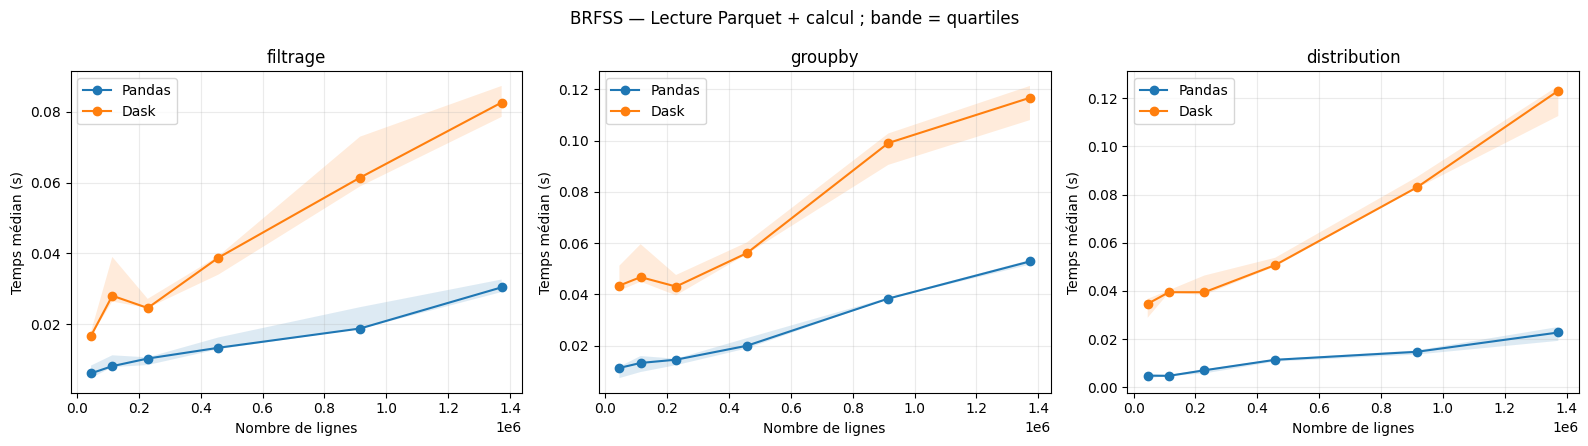

technologie                        Dask    Pandas  ratio_Pandas_sur_Dask
facteur n_lignes operation                                              
0.10    45767    distribution  0.034678  0.004834               0.139382
                 filtrage      0.016816  0.006206               0.369027
                 groupby       0.043427  0.011288               0.259927
0.25    114417   distribution  0.039480  0.004757               0.120504
                 filtrage      0.028092  0.008226               0.292822
                 groupby       0.046718  0.013225               0.283070
0.50    228835   distribution  0.039478  0.007059               0.178819
                 filtrage      0.024632  0.010373               0.421108
                 groupby       0.043044  0.014503               0.336924
1.00    457670   distribution  0.050748  0.011415               0.224931
                 filtrage      0.038836  0.013413               0.345372
                 groupby       0.056075  0.019933               0.355482
2.00    915340   distribution  0.082968  0.014735               0.177604
                 filtrage      0.061396  0.018843               0.306909
                 groupby       0.099052  0.038351               0.387182
3.00    1373010  distribution  0.123148  0.022754               0.184769
                 filtrage      0.082586  0.030456               0.368780
                 groupby       0.116707  0.052844               0.452789

Ratio > 1 : Dask plus rapide ; ratio < 1 : Pandas plus rapide.


In [6]:
resume = mesures.groupby(["facteur", "n_lignes", "operation", "technologie"])["temps_s"].agg(
    mediane="median", minimum="min", maximum="max",
    q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75),
).reset_index()
resume.to_csv(RESULTS / "resume.csv", index=False)
display(resume)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, nom in zip(axes, COLONNES_OPERATIONS):
    for moteur in MOTEURS:
        serie = resume[(resume["operation"] == nom) & (resume["technologie"] == moteur)].sort_values("n_lignes")
        ax.plot(serie["n_lignes"], serie["mediane"], marker="o", label=moteur)
        ax.fill_between(serie["n_lignes"], serie["q25"], serie["q75"], alpha=0.15)
    ax.set(title=nom, xlabel="Nombre de lignes", ylabel="Temps médian (s)")
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle("BRFSS — Lecture Parquet + calcul ; bande = quartiles")
fig.tight_layout()
fig.savefig(RESULTS / "courbes_temps.png", dpi=180, bbox_inches="tight")
plt.show()

comparaison = resume.pivot(index=["facteur", "n_lignes", "operation"], columns="technologie", values="mediane")
comparaison["ratio_Pandas_sur_Dask"] = comparaison["Pandas"] / comparaison["Dask"]
display(comparaison)
comparaison.to_csv(RESULTS / "comparaison.csv")
print("Ratio > 1 : Dask plus rapide ; ratio < 1 : Pandas plus rapide.")
